3. سوالات تکلیف

3-1-2 تاثیر استراید و پدینگ

3-1-2-1 معماری ثابتی با دو لایه کانولوشن (3*3، 32 و 64 فیلتر) و یک لایه پولینگ 2*2 بعد از هر لایه در نظر بگیرید. در لایه اول مقادیر استراید را به ترتیب روی 1 و 2 تنظیم کنید (پدینگ را به گونه ای انتخاب کنید که ابعاد خروجی پس از کانولوشن با ورودی برابر یا نصف شود).

الف) ابعاد تنسور خروجی بعد از لایه اول برای هر حالت چقدر است؟ چه تاثیری روی تعداد پارامتر ها و زمان آموزش دارد ؟

ب) آیا دقت نهایی مدل با افزایش استراید تغییر میکند؟ نتایج را در قالب جدول گزارش دهید.

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datetime import datetime
import os
from pathlib import Path
import sys
import time

sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_moons_data, get_mnist_data
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)

In [2]:
X_train, X_test, y_train, y_test, train_loader, test_loader = get_mnist_data(batch_size=64)

In [10]:
class CNNWithStride(nn.Module):
    def __init__(self, stride1=1, padding1='same'):
        super(CNNWithStride, self).__init__()
        if stride1 == 1 and padding1 == 'same':
            pad = 'same'
        elif stride1 == 2:
            # For kernel=3, stride=2, padding=1 gives output size 14x14 (half of 28)
            pad = 1
        else:
            pad = 0  # valid padding

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=stride1, padding=pad)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding='same')
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)
        
        self._initialize_fc()

    def _initialize_fc(self):
        dummy = torch.zeros(1, 1, 28, 28)
        with torch.no_grad():
            x = self.pool1(self.relu1(self.conv1(dummy)))
            x = self.pool2(self.relu2(self.conv2(x)))
            self.flatten_size = x.view(1, -1).size(1)
        self.fc = nn.Linear(self.flatten_size, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x

def compute_output_shape(input_size=28, kernel=3, stride=1, padding='same'):
    if padding == 'same' and stride == 1:
        return input_size
    elif stride == 2 and padding == 1:
        # For our manual case
        return (input_size + 2 - kernel) // stride + 1
    else:
        return (input_size - kernel) // stride + 1


In [12]:
def train_model(model, epochs=5, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.to(device)
    train_acc_history = []
    test_acc_history = []
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        correct_train = 0
        total_train = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
        train_acc = 100 * correct_train / total_train
        
        model.eval()
        correct_test = 0
        total_test = 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs, 1)
                total_test += labels.size(0)
                correct_test += (predicted == labels).sum().item()
        test_acc = 100 * correct_test / total_test
        train_acc_history.append(train_acc)
        test_acc_history.append(test_acc)
        if (epoch+1)%5==0:print(f"Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
    elapsed = time.time() - start_time
    print(f"Training time: {elapsed:.2f} sec")
    return train_acc_history, test_acc_history, elapsed


In [14]:
stride_configs = [
    {'stride': 1, 'padding': 'same', 'desc': 'stride=1, padding=same'},
    {'stride': 2, 'padding': 1, 'desc': 'stride=2, padding=1 (output half)'}
]

results_stride = []

for cfg in stride_configs:
    print(f"\n===== Experiment: {cfg['desc']} =====")
    model = CNNWithStride(stride1=cfg['stride'], padding1=cfg['padding'])
    out_h = compute_output_shape(28, 3, cfg['stride'], cfg['padding'])
    print(f"Output size after conv1: {out_h}x{out_h}")
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable parameters: {num_params:,}")
    train_hist, test_hist, train_time = train_model(model, epochs=20, lr=0.001)
    final_test_acc = test_hist[-1]
    results_stride.append({
        'config': cfg['desc'],
        'stride': cfg['stride'],
        'padding': cfg['padding'],
        'output_size_conv1': out_h,
        'num_params': num_params,
        'final_test_acc': final_test_acc,
        'train_hist': train_hist,
        'test_hist': test_hist,
        'elapsed_time':train_time
    })




===== Experiment: stride=1, padding=same =====
Output size after conv1: 28x28
Trainable parameters: 50,186
Epoch 5/20 | Train Acc: 99.30% | Test Acc: 98.91%
Epoch 10/20 | Train Acc: 99.72% | Test Acc: 99.03%
Epoch 15/20 | Train Acc: 99.85% | Test Acc: 98.98%
Epoch 20/20 | Train Acc: 99.93% | Test Acc: 99.20%
Training time: 283.86 sec

===== Experiment: stride=2, padding=1 (output half) =====
Output size after conv1: 14x14
Trainable parameters: 24,586
Epoch 5/20 | Train Acc: 98.96% | Test Acc: 98.63%
Epoch 10/20 | Train Acc: 99.54% | Test Acc: 98.48%
Epoch 15/20 | Train Acc: 99.71% | Test Acc: 98.42%
Epoch 20/20 | Train Acc: 99.84% | Test Acc: 98.64%
Training time: 274.97 sec


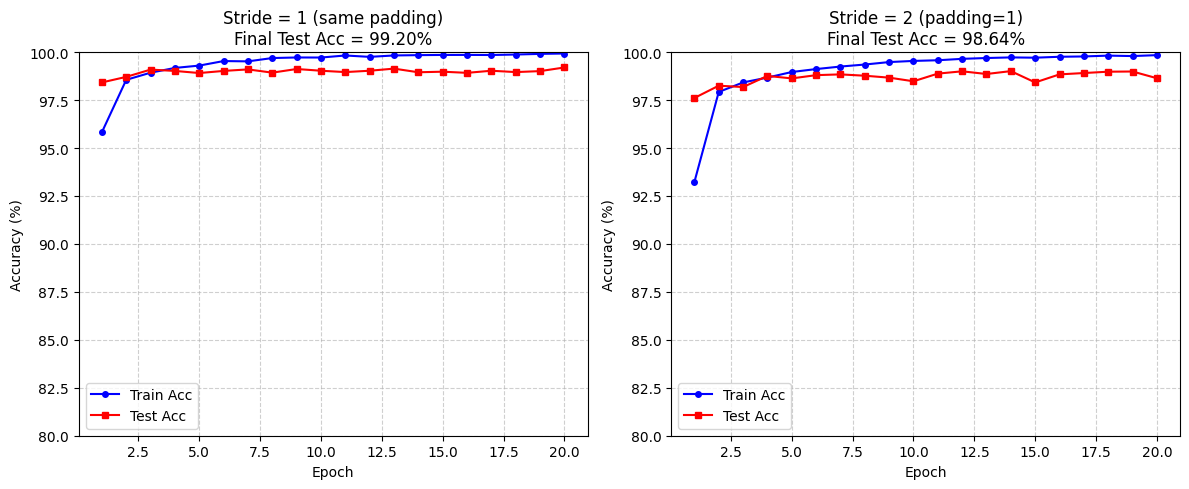

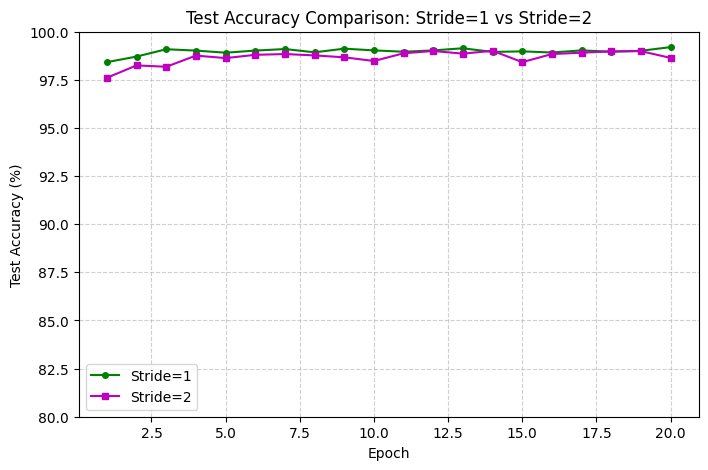

In [15]:
import matplotlib.pyplot as plt

# Plot accuracy curves for both stride configurations
plt.figure(figsize=(12, 5))

# Plot for stride=1
res1 = results_stride[0]  # stride=1
epochs_range = range(1, len(res1['train_hist']) + 1)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, res1['train_hist'], 'b-o', label='Train Acc', markersize=4)
plt.plot(epochs_range, res1['test_hist'], 'r-s', label='Test Acc', markersize=4)
plt.title(f"Stride = 1 (same padding)\nFinal Test Acc = {res1['final_test_acc']:.2f}%")
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim([80, 100])

# Plot for stride=2
res2 = results_stride[1]  # stride=2
plt.subplot(1, 2, 2)
plt.plot(epochs_range, res2['train_hist'], 'b-o', label='Train Acc', markersize=4)
plt.plot(epochs_range, res2['test_hist'], 'r-s', label='Test Acc', markersize=4)
plt.title(f"Stride = 2 (padding=1)\nFinal Test Acc = {res2['final_test_acc']:.2f}%")
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim([80, 100])

plt.tight_layout()
plt.savefig('stride_accuracy_curves.png', dpi=150)
plt.show()

# Optionally, combine both test accuracies on one plot for direct comparison
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, res1['test_hist'], 'g-o', label='Stride=1', markersize=4)
plt.plot(epochs_range, res2['test_hist'], 'm-s', label='Stride=2', markersize=4)
plt.title('Test Accuracy Comparison: Stride=1 vs Stride=2')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim([80, 100])
plt.savefig('stride_test_accuracy_comparison.png', dpi=150)
plt.show()

In [16]:

# Display results table for stride
print("\n===== Results: Effect of Stride =====")
df_stride = pd.DataFrame([(r['config'], r['output_size_conv1'], r['num_params'], r['final_test_acc'], r['elapsed_time']) 
                          for r in results_stride],
                         columns=['Configuration', 'Output size after conv1', '#Params', 'Test Acc (%)', 'Training Time (s)'])
print(df_stride.to_string(index=False))
df_stride.to_csv('stride_results.csv', index=False)



===== Results: Effect of Stride =====
                    Configuration  Output size after conv1  #Params  Test Acc (%)  Training Time (s)
           stride=1, padding=same                       28    50186         99.20         283.857538
stride=2, padding=1 (output half)                       14    24586         98.64         274.973389


3-1-2-2 پدینگ را روی دو حالت ‘valid’ (بدون پدینگ) و ‘same’ (پدینگ به طوری که ابعاد ورودی و خروجی از نظر ارتفاع و عرض یکسان بمانند) تنظیم کنید (stride=1).

الف) بدون پدینگ، با چند لایه کانولوشن متوالی (بدون پولینگ) ابعاد تصویر به صفر میرسد؟ این مسئله چه مشکلی در طراحی شبکه های عمیق ایجاد میکند؟

In [17]:
kernel = 3
stride = 1
padding = 0  # valid
size = 28
layers = 0
while size > 0:
    size = (size - kernel) // stride + 1
    layers += 1
    print(f"After {layers} conv layer(s), size = {size}")
    if size <= 0:
        break
print(f"\nWithout padding, image size becomes zero after {layers} convolutional layers.")
print("Problem in deep networks: dimensions shrink rapidly, limiting network depth and losing spatial information at boundaries.")


After 1 conv layer(s), size = 26
After 2 conv layer(s), size = 24
After 3 conv layer(s), size = 22
After 4 conv layer(s), size = 20
After 5 conv layer(s), size = 18
After 6 conv layer(s), size = 16
After 7 conv layer(s), size = 14
After 8 conv layer(s), size = 12
After 9 conv layer(s), size = 10
After 10 conv layer(s), size = 8
After 11 conv layer(s), size = 6
After 12 conv layer(s), size = 4
After 13 conv layer(s), size = 2
After 14 conv layer(s), size = 0

Without padding, image size becomes zero after 14 convolutional layers.
Problem in deep networks: dimensions shrink rapidly, limiting network depth and losing spatial information at boundaries.


ب) تاثیر پدینگ روی دقت نهایی مدل را ارزیابی کنید.

In [19]:

class CNNWithPadding(nn.Module):
    def __init__(self, padding_mode='same'):
        super(CNNWithPadding, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=padding_mode)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=padding_mode)
        self.relu2 = nn.ReLU()
        # No pooling in this part for the sequential analysis
        # But for accuracy evaluation we still need pooling? The question asks for effect on final accuracy.
        # We'll keep pooling as in previous architecture? Actually they ask: without pooling, after how many layers dimensions become zero.
        # Then separately evaluate impact of padding on final accuracy. We'll use same architecture as before (with pooling) for accuracy comparison.
        self.pool = nn.MaxPool2d(2, 2)
        # We'll add a final FC after two conv layers + pooling
        self._initialize_fc()

    def _initialize_fc(self):
        dummy = torch.zeros(1, 1, 28, 28)
        with torch.no_grad():
            x = self.pool(self.relu2(self.conv2(self.relu1(self.conv1(dummy)))))
            self.flatten_size = x.view(1, -1).size(1)
        self.fc = nn.Linear(self.flatten_size, 10)

    def forward(self, x):
        x = self.relu1(self.conv1(x))
        x = self.relu2(self.conv2(x))
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


In [22]:
# Train
def train_padding_model(model, epochs=5, lr=0.001):
	criterion = nn.CrossEntropyLoss()
	optimizer = optim.Adam(model.parameters(), lr=lr)
	model.to(device)
	train_acc_hist = []
	test_acc_hist = []
	for epoch in range(epochs):
		model.train()
		correct_train = 0
		total_train = 0
		for images, labels in train_loader:
			images, labels = images.to(device), labels.to(device)
			optimizer.zero_grad()
			outputs = model(images)
			loss = criterion(outputs, labels)
			loss.backward()
			optimizer.step()
			_, predicted = torch.max(outputs, 1)
			total_train += labels.size(0)
			correct_train += (predicted == labels).sum().item()
		train_acc = 100 * correct_train / total_train
		
		model.eval()
		correct_test = 0
		total_test = 0
		with torch.no_grad():
			for images, labels in test_loader:
				images, labels = images.to(device), labels.to(device)
				outputs = model(images)
				_, predicted = torch.max(outputs, 1)
				total_test += labels.size(0)
				correct_test += (predicted == labels).sum().item()
		test_acc = 100 * correct_test / total_test
		train_acc_hist.append(train_acc)
		test_acc_hist.append(test_acc)
		if (epoch+1)%5==0:print(f"Epoch {epoch+1}/{epochs} | Train Acc: {train_acc:.2f}% | Test Acc: {test_acc:.2f}%")
	return train_acc_hist, test_acc_hist


In [23]:

# Part (b): Evaluate effect of padding on final accuracy (with pooling)
padding_configs = [
    {'padding': 'same', 'desc': 'padding=same'},
    {'padding': 0, 'desc': 'padding=valid (no padding)'}
]

results_padding = []

for cfg in padding_configs:
    print(f"\n===== Experiment: {cfg['desc']} =====")
    model = CNNWithPadding(padding_mode=cfg['padding'])
    num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Number of parameters: {num_params:,}")
    
    train_hist, test_hist = train_padding_model(model, epochs=20, lr=0.001)
    final_test_acc = test_hist[-1]
    results_padding.append({
        'config': cfg['desc'],
        'num_params': num_params,
        'final_test_acc': final_test_acc,
        'train_hist': train_hist,
        'test_hist': test_hist
    })



===== Experiment: padding=same =====
Number of parameters: 144,266
Epoch 5/20 | Train Acc: 99.53% | Test Acc: 98.88%
Epoch 10/20 | Train Acc: 99.83% | Test Acc: 98.76%
Epoch 15/20 | Train Acc: 99.89% | Test Acc: 98.79%
Epoch 20/20 | Train Acc: 99.94% | Test Acc: 98.58%

===== Experiment: padding=valid (no padding) =====
Number of parameters: 110,986
Epoch 5/20 | Train Acc: 99.49% | Test Acc: 98.64%
Epoch 10/20 | Train Acc: 99.81% | Test Acc: 98.83%
Epoch 15/20 | Train Acc: 99.90% | Test Acc: 98.49%
Epoch 20/20 | Train Acc: 99.95% | Test Acc: 98.64%



===== Results: Effect of Padding =====
              Padding Mode  #Params  Test Acc (%)
              padding=same   144266         98.58
padding=valid (no padding)   110986         98.64


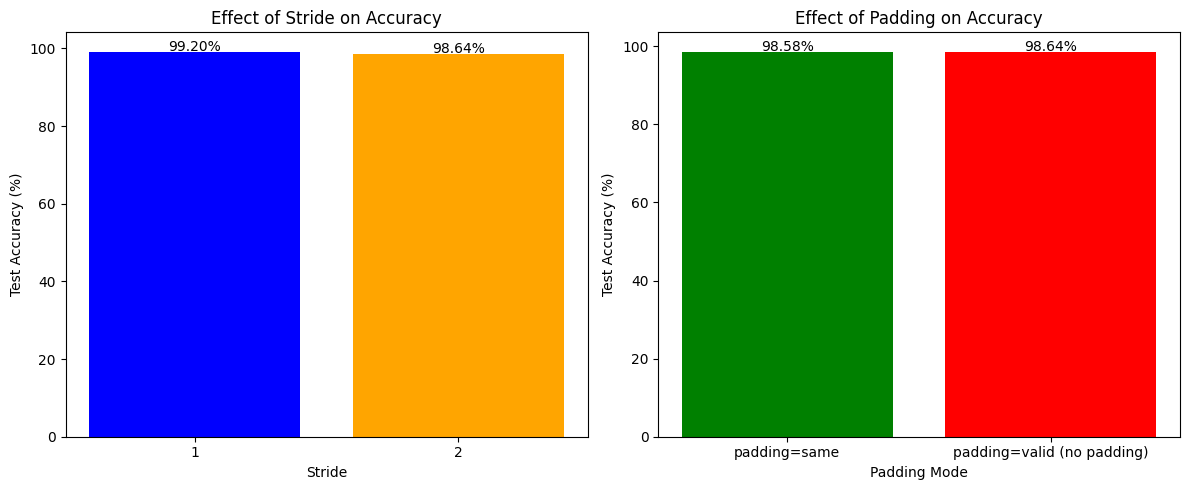


All results saved: stride_results.csv, padding_results.csv, stride_padding_comparison.png


In [24]:

# Display results table for padding
print("\n===== Results: Effect of Padding =====")
df_padding = pd.DataFrame([(r['config'], r['num_params'], r['final_test_acc']) for r in results_padding],
                          columns=['Padding Mode', '#Params', 'Test Acc (%)'])
print(df_padding.to_string(index=False))
df_padding.to_csv('padding_results.csv', index=False)

# Plot comparison of test accuracy for stride and padding
plt.figure(figsize=(12, 5))

# Stride comparison
plt.subplot(1, 2, 1)
strides = [r['stride'] for r in results_stride]
accs = [r['final_test_acc'] for r in results_stride]
plt.bar([str(s) for s in strides], accs, color=['blue', 'orange'])
plt.xlabel('Stride')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Stride on Accuracy')
for i, acc in enumerate(accs):
    plt.text(i, acc + 0.2, f'{acc:.2f}%', ha='center')

# Padding comparison
plt.subplot(1, 2, 2)
pad_names = [r['config'] for r in results_padding]
pad_accs = [r['final_test_acc'] for r in results_padding]
plt.bar(pad_names, pad_accs, color=['green', 'red'])
plt.xlabel('Padding Mode')
plt.ylabel('Test Accuracy (%)')
plt.title('Effect of Padding on Accuracy')
for i, acc in enumerate(pad_accs):
    plt.text(i, acc + 0.2, f'{acc:.2f}%', ha='center')

plt.tight_layout()
plt.savefig('stride_padding_comparison.png', dpi=150)
plt.show()

print("\nAll results saved: stride_results.csv, padding_results.csv, stride_padding_comparison.png")